In [17]:
import pickle
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.neighbors import NearestNeighbors

In [18]:
TRAIN_SIZE = 10000     
TEST_SIZE = 500   
K_NEIGHBORS = 10
SEED = 42
N_THREADS = 1


In [19]:
import gc
import os
import threading

import faiss
import psutil
from threadpoolctl import threadpool_limits



MB = 1024 * 1024
_process = psutil.Process(os.getpid())
threadpool_limits(N_THREADS)
faiss.omp_set_num_threads(N_THREADS)



def get_process_memory_mb():
    return _process.memory_info().rss / MB


class MemoryMeter:
    """RSS процесса до блока, после блока и максимум внутри блока.

    Разность «после − до» не видит временные буферы, освобождённые к концу блока
    (матрица расстояний, хеши запросов), поэтому RSS дополнительно опрашивается
    в фоновом потоке и фиксируется пик. Перед замером собирается мусор, чтобы
    в «до» не попали объекты, ожидающие удаления.
    """

    def __init__(self, interval=0.001):
        self.interval = interval

    def __enter__(self):
        gc.collect()
        self.before = _process.memory_info().rss
        self._stop = threading.Event()
        self._thread = threading.Thread(target=self._poll, daemon=True)
        self._thread.start()
        return self

    def _poll(self):
        while not self._stop.is_set():
            self._stop.wait(self.interval)

    def __exit__(self, *exc):
        self._stop.set()
        self._thread.join()
        self.after = _process.memory_info().rss

    @property
    def delta_mb(self):
        return (self.after - self.before) / MB


def measure_time(func):
    t0 = time.perf_counter()
    result = func()
    time_elapsed = time.perf_counter() - t0
    return result, float(time_elapsed)

In [20]:
import os
import urllib.request

DATASET_PATH = "glove-100-angular.hdf5"
DATASET_URL = "https://ann-benchmarks.com/glove-100-angular.hdf5"

if not os.path.exists(DATASET_PATH):
    request = urllib.request.Request(
        DATASET_URL,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    with urllib.request.urlopen(request, timeout=120) as response:
        with open(DATASET_PATH, "wb") as f:
            f.write(response.read())

    print("Датасет скачан!")

else:
    print("Файл уже существует.")


Файл уже существует.


In [21]:

import numpy as np
import h5py
import os

DATASET_PATH = r"D:\Programming\Data-analysis\glove-100-angular.hdf5"

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(
        f"Файл не найден: {DATASET_PATH}. Проверь путь."
    )

with h5py.File(DATASET_PATH, "r") as f:
    print("Ключи датасета:", list(f.keys()))

    X_train = np.asarray(f["train"][:TRAIN_SIZE], dtype=np.float32)
    X_test = np.asarray(f["test"][:TEST_SIZE], dtype=np.float32)

print(f"Размер обучающей выборки (Train): {X_train.shape}")
print(f"Размер тестовой выборки (Test):   {X_test.shape}")


Ключи датасета: ['distances', 'neighbors', 'test', 'train']
Размер обучающей выборки (Train): (10000, 100)
Размер тестовой выборки (Test):   (500, 100)


In [22]:
def normalize_rows(X):
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    return X / np.maximum(norms, 1e-12)

X_train = normalize_rows(X_train)
X_test = normalize_rows(X_test)

print("Train:", X_train.shape)
print("Test: ", X_test.shape)

Train: (10000, 100)
Test:  (500, 100)


In [23]:
with MemoryMeter() as mem_fit:
    start_time_fit = time.perf_counter()

    nn_brute_force = NearestNeighbors(n_neighbors=K_NEIGHBORS, algorithm="brute", metric="euclidean")
    nn_brute_force.fit(X_train)

    execution_time_fit = time.perf_counter() - start_time_fit
memory_fit_brut_force = mem_fit.delta_mb
index_mb_brut_force = nn_brute_force._fit_X.nbytes / MB


def search_brut_force():
    return nn_brute_force.kneighbors(X_test)


(distances, indices), execution_time_test = measure_time(search_brut_force)

with MemoryMeter() as mem_search:
    search_brut_force()

print(f"Время обучения:             {execution_time_fit:.4f} сек")
print(f"Время поиска:               {execution_time_test:.4f} сек "
      f"({execution_time_test / len(X_test) * 1e3:.3f} мс/запрос)")
print(f"Размер индекса (тестовая + обучающая выборки): {index_mb_brut_force:.2f} MB")

Время обучения:             0.0015 сек
Время поиска:               0.0680 сек (0.136 мс/запрос)
Размер индекса (тестовая + обучающая выборки): 3.81 MB


In [24]:
from pathlib import Path
BASE_WEIGHT_PATH = Path("./weights")
BASE_WEIGHT_PATH.mkdir(parents=True, exist_ok=True)

full_path = BASE_WEIGHT_PATH / "mnist_exact_k10-glove.pkl"

payload = {
    "indices": indices,
    "distances": distances,  
    "K": K_NEIGHBORS,
    "execution_time": execution_time_test,
    "index_memory_mb": index_mb_brut_force,
    "n_train": X_train.shape[0],
    "n_test": X_test.shape[0],
}

with open(full_path, "wb") as f:
    pickle.dump(payload, f)

print(f"Результаты точного поиска сохранены в файл: {full_path}")

Результаты точного поиска сохранены в файл: weights\mnist_exact_k10-glove.pkl


In [25]:
def load_ground_truth(pkl_filepath: str):
    with open(pkl_filepath, "rb") as f:
        gt_data = pickle.load(f)
    return gt_data["indices"]


def calculate_recall_at_k(exact_indices: np.ndarray, approx_indices: np.ndarray, k: int = K_NEIGHBORS) -> float:
    exact_k = exact_indices[:, :k]
    approx_k = approx_indices[:, :k]

    n_queries = exact_k.shape[0]
    total_recall = 0.0

    for i in range(n_queries):
        true_set = set(exact_k[i])
        found_set = set(approx_k[i])

        intersection = len(true_set.intersection(found_set))
        total_recall += intersection / k

    return total_recall / n_queries

## Flyhash

## FlyHash optim

In [31]:
import faiss
from scipy import sparse
from flyhash import FlyHash

exact_indices = load_ground_truth(full_path)

INPUT_DIM = X_train.shape[1]
HASH_DIM = 7840
SPARSITY = 0.05

fly = FlyHash(
    input_dim=INPUT_DIM,
    hash_dim=HASH_DIM,
    sparsity=SPARSITY,
    seed=SEED,
)


def hash_to_packed(model, X):
    hs = model(X)
    if sparse.issparse(hs):
        hs = hs.toarray()
    bits = (np.asarray(hs) > 0).astype(np.uint16)
    return np.ascontiguousarray(np.packbits(bits, axis=1))


with MemoryMeter() as mem_fit:
    t0 = time.perf_counter()
    train_hashes = hash_to_packed(fly, X_train)
    index_fly = faiss.IndexBinaryFlat(HASH_DIM)
    index_fly.add(train_hashes)
    time_hash_train_fly = time.perf_counter() - t0
memory_fit_fly_mb = mem_fit.delta_mb
index_fly_mb = (index_fly.ntotal * index_fly.code_size + fly.projection_matrix.nbytes) / MB


def search_fly():
    test_hashes = hash_to_packed(fly, X_test)
    return index_fly.search(test_hashes, K_NEIGHBORS)


(_, approx_indices_fly), time_search_fly = measure_time(search_fly)


test_hashes, time_hash_test_fly = measure_time(lambda: hash_to_packed(fly, X_test))
_, time_hamming_fly = measure_time(lambda: index_fly.search(test_hashes, K_NEIGHBORS))


with MemoryMeter() as mem_search:
    search_fly()


print("=== Результаты FlyHash ===")
print(f"Параметры: hash_dim={HASH_DIM}, sparsity={SPARSITY}")
print(f"Хеширование Train (Время обучения):  {time_hash_train_fly:.4f} сек")
print(f"Время поиска (Inc. Test Hash):       {time_search_fly:.4f} сек "
      f"({time_search_fly / len(X_test) * 1e3:.3f} мс/запрос)")
print(f"  хеширование Test:                  {time_hash_test_fly:.4f} сек")
print(f"  поиск по Хэммингу:                 {time_hamming_fly:.4f} сек")
print(f"Размер индекса (коды + проекции):    {index_fly_mb:.2f} MB")

for k in (1, 5, 10):
    recall = calculate_recall_at_k(exact_indices, approx_indices_fly, k)
    print(f"Recall@{k}: {recall:.4f}")

=== Результаты FlyHash ===
Параметры: hash_dim=7840, sparsity=0.05
Хеширование Train (Время обучения):  2.4864 сек
Время поиска (Inc. Test Hash):       0.7117 сек (1.423 мс/запрос)
  хеширование Test:                  0.1159 сек
  поиск по Хэммингу:                 0.5938 сек
Размер индекса (коды + проекции):    10.09 MB
Recall@1: 0.0000
Recall@5: 0.0008
Recall@10: 0.0018


### HNSW

In [32]:
import hnswlib

BASE_WEIGHT_PATH = Path("./weights")
full_path = BASE_WEIGHT_PATH / "mnist_exact_k10-glove.pkl"

X_train = np.ascontiguousarray(X_train, dtype=np.float32)
X_test  = np.ascontiguousarray(X_test,  dtype=np.float32)


with open(full_path, "rb") as f:
    gt_data = pickle.load(f)
exact_indices = np.asarray(gt_data["indices"])


dim = X_train.shape[1]
num_elements = X_train.shape[0]

M = 16
EF_CONSTRUCTION = 200
EF_SEARCH = 50


with MemoryMeter() as mem_fit:
    t0 = time.perf_counter()

    p = hnswlib.Index(space="l2", dim=dim)
    p.init_index(max_elements=num_elements, ef_construction=EF_CONSTRUCTION, M=M,
                 random_seed=SEED)
    p.set_num_threads(N_THREADS)
    p.add_items(X_train)
    p.set_ef(EF_SEARCH)

    time_fit_hnsw = time.perf_counter() - t0
index_mb_hnsw = p.index_file_size() / MB


def search_hnsw():
    return p.knn_query(X_test, k=K_NEIGHBORS)  # Здесь поиск


(hnsw_indices, _), time_test_hnsw = measure_time(search_hnsw)

with MemoryMeter() as mem_search:
    search_hnsw()


print("=== Результаты HNSW ===")
print(f"Параметры: M={M}, ef_construction={EF_CONSTRUCTION}, ef={EF_SEARCH}")
print(f"Время построения индекса:  {time_fit_hnsw:.4f} сек")
print(f"Время поиска:              {time_test_hnsw:.4f} сек "
      f"({time_test_hnsw / len(X_test) * 1e3:.3f} мс/запрос)")
print(f"Размер индекса:            {index_mb_hnsw:.2f} MB")

for k in (1, 5, 10):
    print(f"Recall@{k}: {calculate_recall_at_k(exact_indices, hnsw_indices, k):.4f}")

=== Результаты HNSW ===
Параметры: M=16, ef_construction=200, ef=50
Время построения индекса:  2.4098 сек
Время поиска:              0.0340 сек (0.068 мс/запрос)
Размер индекса:            5.23 MB
Recall@1: 0.9440
Recall@5: 0.9164
Recall@10: 0.8900


### IVFPQ

In [35]:
import faiss

BASE_WEIGHT_PATH = Path("./weights")
full_path = BASE_WEIGHT_PATH / "mnist_exact_k10-glove.pkl"

X_train = np.ascontiguousarray(X_train, dtype=np.float32)
X_test  = np.ascontiguousarray(X_test,  dtype=np.float32)


with open(full_path, "rb") as f:
    gt_data = pickle.load(f)
exact_indices = np.asarray(gt_data["indices"])


dim = X_train.shape[1]
nlist = 100
m_subquantizers = 25
bits_per_code = 8
nprobe = 10


quantizer = faiss.IndexFlatL2(dim)
index = faiss.IndexIVFPQ(quantizer, dim, nlist, m_subquantizers, bits_per_code)
index.use_precomputed_table = 0
index.cp.seed = SEED
index.pq.cp.seed = SEED


with MemoryMeter() as mem_fit:
    t0 = time.perf_counter()

    index.train(X_train)
    index.add(X_train)

    time_train_ivfpq = time.perf_counter() - t0

index_ivfpq_mb = faiss.serialize_index(index).nbytes / MB

index.nprobe = nprobe


def search_ivfpq():
    return index.search(X_test, K_NEIGHBORS)


(distances, ivfpq_indices), time_search_ivfpq = measure_time(search_ivfpq)

with MemoryMeter() as mem_search:
    search_ivfpq()

print(f"Параметры: nlist={nlist}, M={m_subquantizers}, "
      f"nbits={bits_per_code}, nprobe={nprobe}")
print(f"Время обучения + добавления: {time_train_ivfpq:.4f} сек")
print(f"Время поиска:                {time_search_ivfpq:.4f} сек "
      f"({time_search_ivfpq / len(X_test) * 1e3:.3f} мс/запрос)")
print(f"Размер индекса:              {index_ivfpq_mb:.2f} MB")

for k in (1, 5, 10):
    print(f"Recall@{k}: {calculate_recall_at_k(exact_indices, ivfpq_indices, k):.4f}")

Параметры: nlist=100, M=25, nbits=8, nprobe=10
Время обучения + добавления: 9.0710 сек
Время поиска:                0.0429 сек (0.086 мс/запрос)
Размер индекса:              0.45 MB
Recall@1: 0.5480
Recall@5: 0.5720
Recall@10: 0.5768


In [36]:
results = {
    "Brut": {
        "indices": exact_indices,     
        "build_time": execution_time_fit,
        "search_time": execution_time_test,
        "index_mb": index_mb_brut_force
    },
    "HNSW": {
        "indices": hnsw_indices,
        "build_time": time_fit_hnsw,
        "search_time": time_test_hnsw,
        "index_mb": index_mb_hnsw
    },
    "IVFPQ": {
        "indices": ivfpq_indices,
        "build_time": time_train_ivfpq,
        "search_time": time_search_ivfpq,
        "index_mb": index_ivfpq_mb,
    },
    "FlyHash": {
        "indices": approx_indices_fly,
        "build_time": time_hash_train_fly,
        "search_time": time_search_fly,
        "index_mb": index_fly_mb
    },
}

n_test = len(X_test)
rows = []
for name, r in results.items():
    row = {
        "Алгоритм": name,
        "Recall@1":  calculate_recall_at_k(exact_indices, r["indices"], 1),
        "Recall@5":  calculate_recall_at_k(exact_indices, r["indices"], 5),
        "Recall@10": calculate_recall_at_k(exact_indices, r["indices"], 10),
        "Время обучения, с":  round(r["build_time"], 4),
        "Время поиска, с":    round(r["search_time"], 4),
        "мс/запрос":          round(r["search_time"] / n_test * 1e3, 4),
        "Индекс, MB":         round(r["index_mb"], 2)
    }
    rows.append(row)

df = pd.DataFrame(rows).set_index("Алгоритм")
print(df.round(4).to_string())

          Recall@1  Recall@5  Recall@10  Время обучения, с  Время поиска, с  мс/запрос  Индекс, MB
Алгоритм                                                                                          
Brut         1.000    1.0000     1.0000             0.0015           0.0680     0.1361        3.81
HNSW         0.944    0.9164     0.8900             2.4098           0.0340     0.0680        5.23
IVFPQ        0.548    0.5720     0.5768             9.0710           0.0429     0.0857        0.45
FlyHash      0.386    0.4892     0.5018             2.4864           0.7117     1.4233       10.09


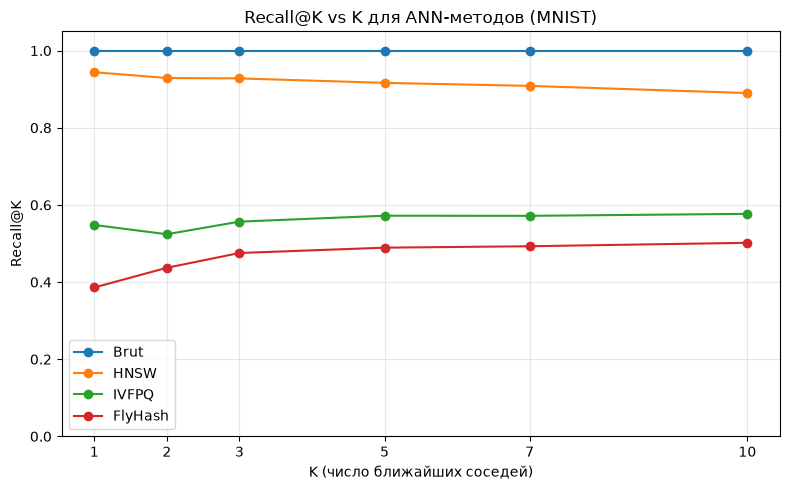

In [37]:
ks = [1, 2, 3, 5, 7, 10]

plt.figure(figsize=(8, 5))
for name, r in results.items():
    recalls = [calculate_recall_at_k(exact_indices, r["indices"], k) for k in ks]
    plt.plot(ks, recalls, marker="o", label=name)

plt.xlabel("K (число ближайших соседей)")
plt.ylabel("Recall@K")
plt.title("Recall@K vs K для ANN-методов (MNIST)")
plt.xticks(ks)
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

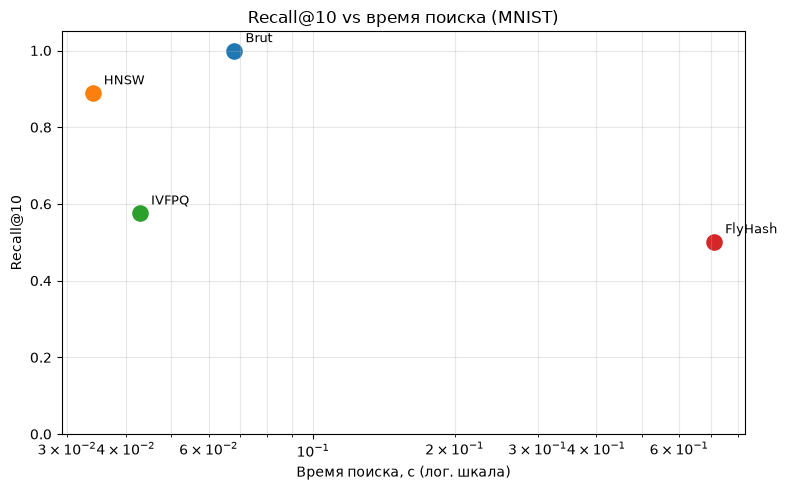

In [38]:
plt.figure(figsize=(8, 5))
for name, r in results.items():
    r10 = calculate_recall_at_k(exact_indices, r["indices"], 10)
    plt.scatter(r["search_time"], r10, s=120, label=name)
    plt.annotate(name, (r["search_time"], r10),
                 textcoords="offset points", xytext=(8, 6), fontsize=9)

plt.xlabel("Время поиска, с (лог. шкала)")
plt.ylabel("Recall@10")
plt.title("Recall@10 vs время поиска (MNIST)")
plt.xscale("log")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

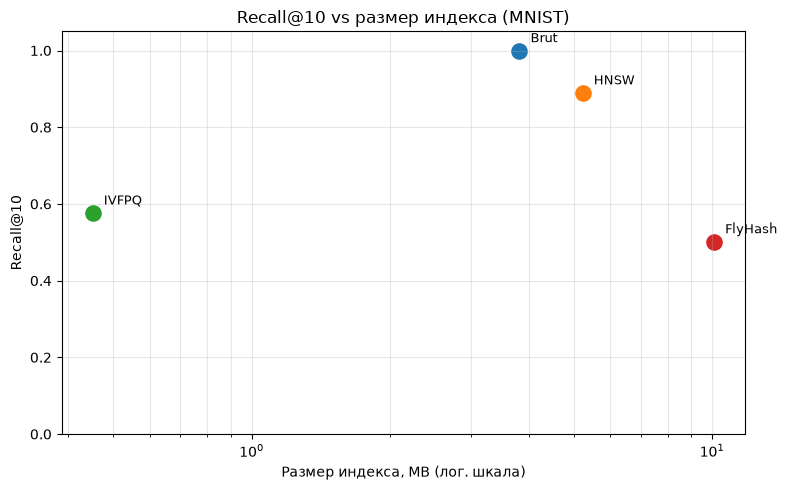

In [39]:
plt.figure(figsize=(8, 5))
for name, r in results.items():
    r10 = calculate_recall_at_k(exact_indices, r["indices"], 10)
    plt.scatter(r["index_mb"], r10, s=120, label=name)
    plt.annotate(name, (r["index_mb"], r10),
                 textcoords="offset points", xytext=(8, 6), fontsize=9)

plt.xlabel("Размер индекса, MB (лог. шкала)")
plt.ylabel("Recall@10")
plt.title("Recall@10 vs размер индекса (MNIST)")
plt.xscale("log")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()